# GPU rental market: single-GPU deep dive

Every provider's price for one GPU, how the indices summarise them, the spread between providers and rental tiers, and the distribution of price changes.

## Parameters

In [1]:
GPU = "H100_SXM"                 # e.g. "H200", "B200", "A100_SXM_80GB"
HIGHLIGHT = ["runpod", "lambda", "nebius"]  # providers drawn as labelled lines
LADDER_DAYS = 7                  # window for the price-by-provider chart
TIER_DAYS = 30                   # window for the price-by-tier chart
RETURN_HORIZON_DAYS = 7          # horizon for the price-change histogram

In [2]:
%matplotlib inline
import pandas as pd

from compute_options.analytics import market_viz as mv

mv.apply_style()
pd.set_option("display.width", 160)
data = mv.MarketData()

mv.summary_table(data, [GPU])

,index ($/GPU-hr),avg posted ($/GPU-hr),Ornn transacted,1M,3M,since start,"vol (weekly, ann.)",providers today,history from
GPU,,,,,,,,,
H100_SXM,$3.76,$3.64,$2.54,+0.7%,+13.5%,+15.7%,19%,23,2026-02-11


## Provider prices and indices

Grey dots are individual providers' daily prices. The coloured line is the price index, the thin grey line the average posted price, and the dashed black line Ornn's transacted index.

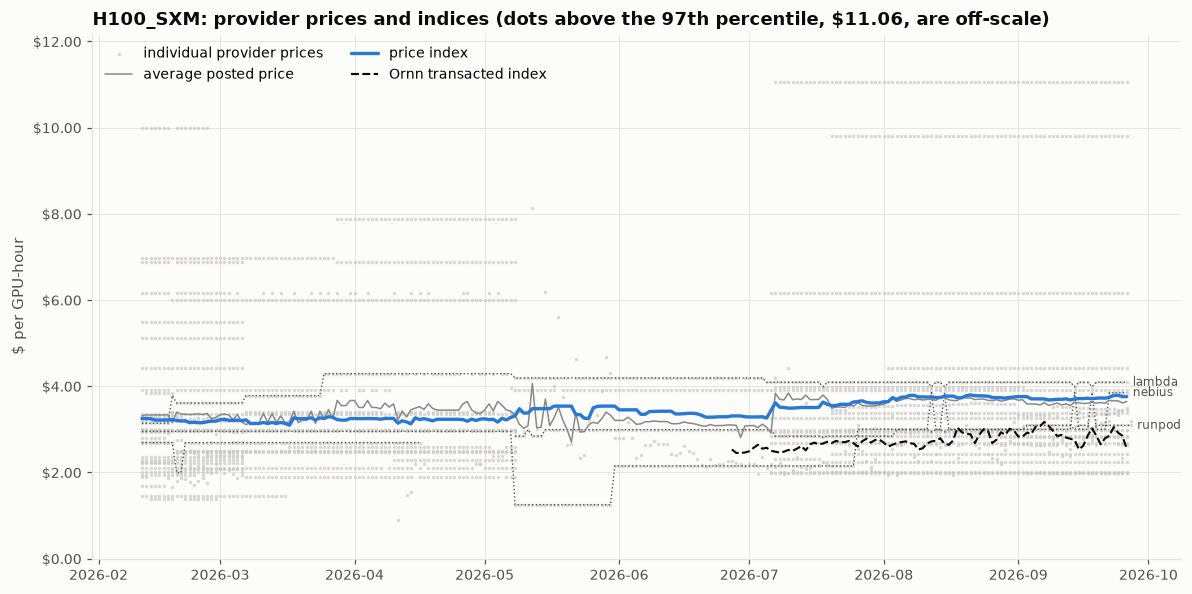

In [3]:
mv.plot_gpu_prices(data, GPU, HIGHLIGHT);

## Price by provider

On-demand price per provider over the last week, against today's price index. Hyperscalers (AWS, Azure, GCP) typically sit well above specialist GPU clouds.

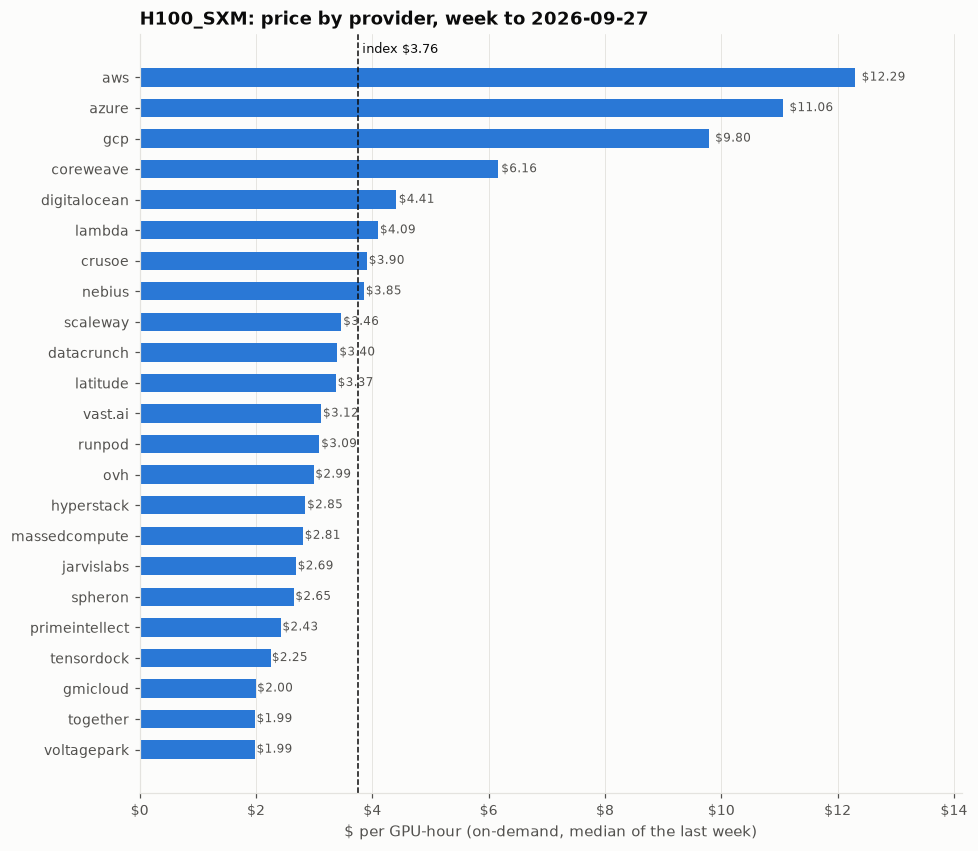

In [4]:
mv.plot_provider_ladder(data, GPU, LADDER_DAYS);

## Price by rental tier

Spot capacity can be interrupted and is cheaper; serverless is billed per second and carries a premium. Only on-demand, secure and community prices feed the index.

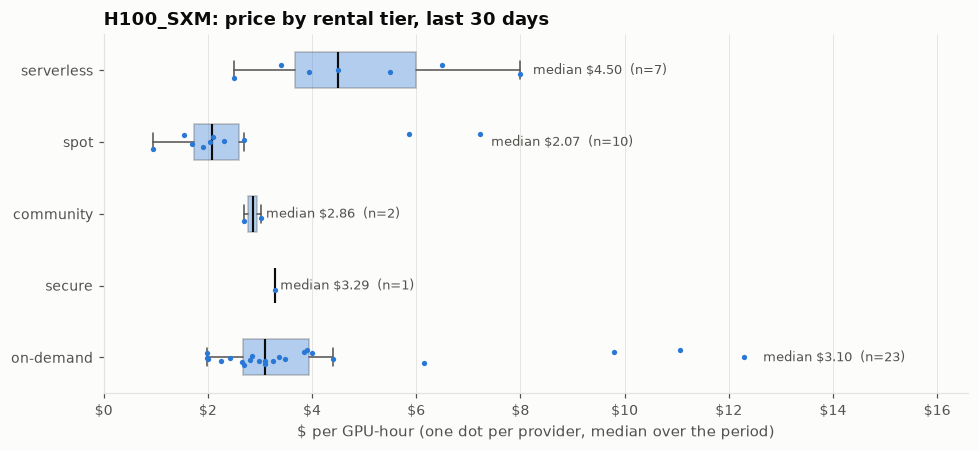

In [5]:
mv.plot_tiers(data, GPU, TIER_DAYS);

## Distribution of price changes

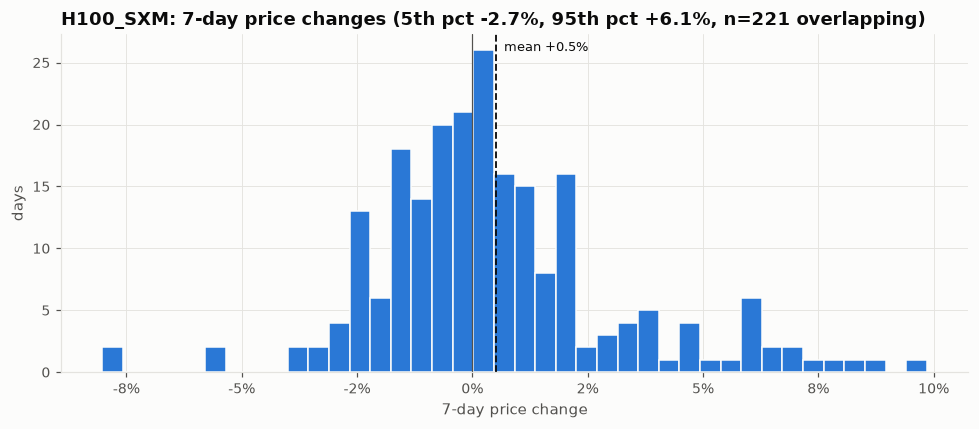

In [6]:
mv.plot_return_distribution(data, GPU, RETURN_HORIZON_DAYS);